# Deep learning for healthcare, session 2
# Does the neural network earn its place?

**Question for today:** on the same ICU patients, does a neural network predict 7-day in-hospital death better than the Cox model and random forest from notebook 03, by enough to justify being harder to understand?

A fair answer needs more than "which score is highest". We ask
1. Is the difference larger than chance, given only about 40 deaths in the test set?
2. Are the risk numbers trustworthy (calibration)?
3. What happens to workload and missed deaths when we act on the alerts?
4. Do the models flag the **same** patients?

| Part | What we do | Approx. time |
|---|---|---|
| 1 | Rules of a fair comparison, data and split | 10 min |
| 2 | Fit four models: Cox, logistic regression, random forest, neural network | 15 min |
| 3 | Ranking, uncertainty and calibration | 15 min |
| 4 | The weighted-loss trap | 10 min |
| 5 | Two ways to set alerts: same threshold, same capacity | 15 min |
| 6 | What summaries hide, and the verdict | 15 min |

## Setup

Locally: create and activate the Conda environment in `environment.yml` as described in the README. In Colab, uncomment the install line

In [1]:
# %pip install lifelines            # uncomment in Google Colab
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from lifelines import CoxPHFitter

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, GREEN, LIME, GREY, RED, ORANGE = "#0b1f4b", "#00a37a", "#9ccf00", "#9aa3ad", "#d1495b", "#f28e2b"
COLORS = {"Cox": NAVY, "Logistic": "#4e79a7", "RandomForest": GREEN, "NeuralNet": ORANGE}

# 1. Rules of a fair comparison

| Rule | Why it matters |
|---|---|
| Same patients, same split as notebook 03 | Differences come from the models, not from luck in who landed in the test set |
| Same inputs: first-48-hour summaries only | All models see the same information. Known weakness shared with notebook 03: the outcome counts from admission, so 20 of 208 day-7 deaths happen inside the 48-hour input window |
| Preprocessing learned on training patients only | Test patients must stay unseen |
| Settings and calibration chosen on training or validation patients | The test set is used once, at the end |
| Paired comparison on the same test patients, with 95% confidence intervals | Shows whether a gap is larger than chance |

> **Honesty note:** the test patients were already examined in notebook 03. This comparison is a teaching exercise, not a fresh independent validation

In [2]:
URL = "https://raw.githubusercontent.com/IE-ML-for-Healthcare/ICU_Survival_analysis/main/PhysionetChallenge2012-set-a.csv.gz"
local = [p for p in [Path("../ICU_Survival_analysis/PhysionetChallenge2012-set-a.csv.gz"),
                     Path("data/PhysionetChallenge2012-set-a.csv.gz")] if p.exists()]
raw = pd.read_csv(local[0] if local else URL, compression="gzip")
for col in ["SAPS-I", "SOFA"]:
    raw.loc[raw[col] < 0, col] = np.nan
raw = raw[raw["Length_of_stay"].ge(0)].reset_index(drop=True)

H = 7
dur = raw["Length_of_stay"].astype(float).to_numpy()
death = raw["In-hospital_death"].astype(int).to_numpy()
y = ((dur <= H) & (death == 1)).astype(int)
X = raw.drop(columns=["In-hospital_death", "Survival", "Length_of_stay", "recordid"])
FEATURES = X.columns.tolist()

idx = np.arange(len(X))
idx_trval, idx_test = train_test_split(idx, test_size=0.20, stratify=death, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.25, stratify=death[idx_trval], random_state=SEED)
S = {"train": idx_train, "val": idx_val, "test": idx_test}
Y = {s: y[r] for s, r in S.items()}

imputer = SimpleImputer(strategy="median").fit(X.iloc[idx_train])
scaler = StandardScaler().fit(imputer.transform(X.iloc[idx_train]))
XI = {s: pd.DataFrame(imputer.transform(X.iloc[r]), columns=FEATURES) for s, r in S.items()}     # imputed, original units
XS = {s: scaler.transform(XI[s]).astype(np.float32) for s in S}                                   # imputed and scaled
print({s: f"{len(r)} patients, {Y[s].sum()} deaths by day {H}" for s, r in S.items()})

{'train': '2364 patients, 125 deaths by day 7', 'val': '788 patients, 41 deaths by day 7', 'test': '788 patients, 42 deaths by day 7'}


# 2. Four models, from most to least readable

| Model | How it decides | What we can inspect |
|---|---|---|
| **Cox** (two cause-specific models, notebook 02) | Hazard ratios for death and for discharge, combined into a 7-day risk | Every coefficient and the risk formula |
| **Logistic regression** | One weighted sum, then a sigmoid | Every weight |
| **Random forest** (notebook 03 settings) | Average of 200 trees | Each tree, but no single readable summary |
| **Neural network** (session 1 design) | Two hidden layers, dropout, early stopping | Every weight, but no faithful readable account |

Calibration: forest and network scores are adjusted on validation patients with **Platt scaling** (a one-input logistic regression on the score), as in notebook 03. Cox and logistic regression are used as they come

In [3]:
# 2.1 Cox: competing risks of death and discharge, combined into a 7-day cumulative incidence (same as notebooks 02 and 03)
def predict_cif(cph_event, cph_comp, Xdf, t):
    H0e = cph_event.baseline_cumulative_hazard_.iloc[:, 0]; H0c = cph_comp.baseline_cumulative_hazard_.iloc[:, 0]
    tg = np.union1d(H0e.index.values.astype(float), H0c.index.values.astype(float))
    He0 = H0e.reindex(tg).ffill().fillna(0).to_numpy(); Hc0 = H0c.reindex(tg).ffill().fillna(0).to_numpy()
    pe = np.asarray(cph_event.predict_partial_hazard(Xdf)).ravel(); pc = np.asarray(cph_comp.predict_partial_hazard(Xdf)).ravel()
    He, Hc = np.outer(pe, He0), np.outer(pc, Hc0)
    dHe, dHc = np.outer(pe, np.diff(He0)), np.outer(pc, np.diff(Hc0))
    dH = dHe + dHc
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.where(dH > 0, dHe / dH, 0.0)
    inc = np.exp(-(He[:, :-1] + Hc[:, :-1])) * (1 - np.exp(-dH)) * share
    F = np.zeros((len(Xdf), tg.size)); F[:, 1:] = np.cumsum(inc, axis=1)
    j = int(np.clip(np.searchsorted(tg, float(t), side="right") - 1, 0, tg.size - 1))
    return F[:, j]

df_tr = XI["train"].assign(duration=dur[idx_train], event=death[idx_train])
cox_death = CoxPHFitter(penalizer=0.1).fit(df_tr, "duration", "event")
cox_disc = CoxPHFitter(penalizer=0.1).fit(df_tr.assign(event=1 - df_tr["event"]), "duration", "event")
P = {m: {} for m in COLORS}
for s in S:
    P["Cox"][s] = predict_cif(cox_death, cox_disc, XI[s], H)

# 2.2 Logistic regression with the penalty strength chosen by 5-fold cross-validation on training patients
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
# Imputation and scaling sit inside the pipeline, so each cross-validation fold learns them from its own training part
XR = {s: X.iloc[r].reset_index(drop=True) for s, r in S.items()}
logreg = GridSearchCV(Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                                ("model", LogisticRegression(max_iter=5000))]),
                      {"model__C": np.logspace(-4, 4, 10)}, scoring="neg_log_loss", cv=CV).fit(XR["train"], Y["train"])
for s in S:
    P["Logistic"][s] = logreg.predict_proba(XR[s])[:, 1]

# 2.3 Random forest: notebook 03 grid, tuned by 5-fold cross-validation, then Platt scaling on validation
rf = GridSearchCV(Pipeline([("impute", SimpleImputer(strategy="median")),
                            ("model", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))]),
                  {"model__max_depth": [4, 6, 8], "model__min_samples_leaf": [25, 50]}, scoring="roc_auc", cv=CV, n_jobs=-1).fit(XR["train"], Y["train"])
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).reshape(-1, 1)
RAW = {"RandomForest": {s: rf.predict_proba(XR[s])[:, 1] for s in S}}
print("Random forest settings:", rf.best_params_)

Random forest settings: {'model__max_depth': 8, 'model__min_samples_leaf': 25}


In [4]:
# 2.4 Neural network: session 1 design, trained 5 times with different seeds and averaged (an "ensemble")
def make_mlp(n_in, seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(n_in, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 16), nn.ReLU(), nn.Dropout(0.2), nn.Linear(16, 1))

def train_net(model, Xa, ya, Xv, yv, seed, epochs=1500, lr=0.003, wd=1e-3, patience=100, pos_weight=None):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.BCEWithLogitsLoss(pos_weight=None if pos_weight is None else torch.tensor(float(pos_weight)))
    Xa_t, ya_t, Xv_t, yv_t = torch.tensor(Xa), torch.tensor(ya, dtype=torch.float32), torch.tensor(Xv), torch.tensor(yv, dtype=torch.float32)
    best, state, wait = np.inf, None, 0
    for ep in range(epochs):
        model.train(); opt.zero_grad(); lossf(model(Xa_t).squeeze(1), ya_t).backward(); opt.step()
        model.eval()
        with torch.no_grad(): vl = lossf(model(Xv_t).squeeze(1), yv_t).item()
        if vl < best - 1e-5: best, state, wait = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval(); return model

def predict(model, Xa):
    with torch.no_grad(): return torch.sigmoid(model(torch.tensor(Xa))).numpy().ravel()

SEEDS = range(5)
nets = [train_net(make_mlp(XS["train"].shape[1], s), XS["train"], Y["train"], XS["val"], Y["val"], s) for s in SEEDS]
RAW["NeuralNet"] = {s: np.mean([predict(m, XS[s]) for m in nets], axis=0) for s in S}
single_seed_auc = [roc_auc_score(Y["test"], predict(m, XS["test"])) for m in nets]

# Platt scaling for forest and network, fitted on validation patients only
for m in ["RandomForest", "NeuralNet"]:
    cal = LogisticRegression(C=1e6).fit(logit(RAW[m]["val"]), Y["val"])
    for s in S:
        P[m][s] = cal.predict_proba(logit(RAW[m][s]))[:, 1]
print("Single-network test AUROC by seed:", np.round(single_seed_auc, 3))

Single-network test AUROC by seed: [0.843 0.852 0.849 0.841 0.847]


Why average five networks? Session 1 showed that runs differing only by seed flag different patients. Averaging them is a simple, widely used way to make predictions more stable. It also makes the model five times larger, and no easier to read

# 3. Ranking, uncertainty and calibration

Three scores, all computed on the 788 test patients
- **AUROC:** how well the model ranks patients who die above those who survive (0.5 chance, 1.0 perfect)
- **AUPRC**, area under the precision-recall curve: how well it finds the rare deaths among many survivors. The no-skill baseline equals the death rate, about 0.05
- **Brier score:** average squared error of the risk numbers. Lower is better

**Paired bootstrap:** resample the test patients 2,000 times with replacement and recompute each model's gap from Cox on the same resample. The middle 95% of those gaps is the **95% confidence interval**. If it includes zero, the data do not show which model is better

,AUROC,AUPRC,Brier,mean predicted risk
Cox,0.864,0.267,0.046,0.047
Logistic,0.880,0.281,0.046,0.046
RandomForest,0.863,0.324,0.043,0.046
NeuralNet,0.852,0.238,0.045,0.049
Observed death rate,NaN,NaN,NaN,0.053


,model,metric,gap_vs_Cox,ci_low,ci_high
0,Logistic,AUROC,0.016,-0.012,0.047
1,Logistic,AUPRC,0.014,-0.049,0.079
2,RandomForest,AUROC,-0.001,-0.049,0.051
3,RandomForest,AUPRC,0.057,-0.044,0.162
4,NeuralNet,AUROC,-0.011,-0.048,0.026
5,NeuralNet,AUPRC,-0.029,-0.125,0.043


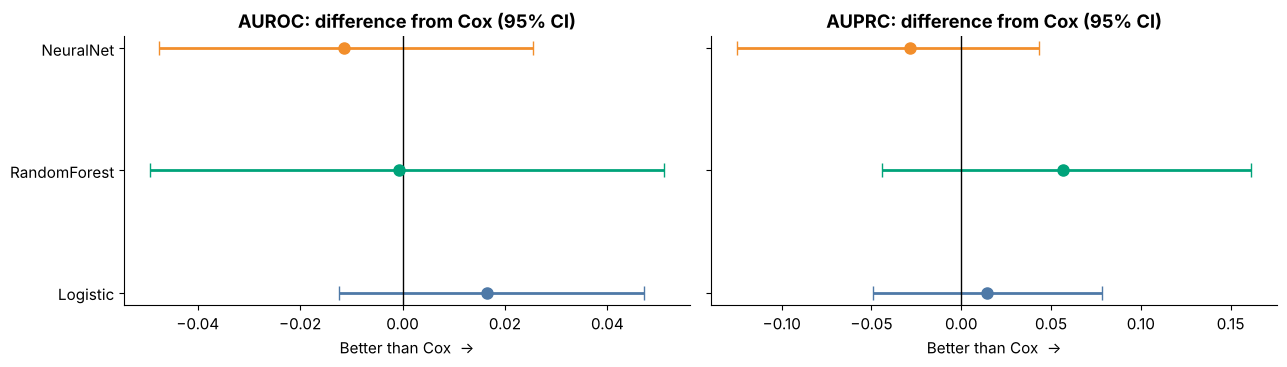

In [5]:
yt = Y["test"]
MODELS = list(COLORS)
tbl = pd.DataFrame({m: {"AUROC": roc_auc_score(yt, P[m]["test"]), "AUPRC": average_precision_score(yt, P[m]["test"]),
                        "Brier": brier_score_loss(yt, P[m]["test"]), "mean predicted risk": P[m]["test"].mean()}
                    for m in MODELS}).T
tbl.loc["Observed death rate", "mean predicted risk"] = yt.mean()
display(tbl.round(3))

rng = np.random.default_rng(SEED)
B = [rng.integers(0, len(yt), len(yt)) for _ in range(2000)]
B = [b for b in B if yt[b].min() != yt[b].max()]
gap_rows = []
for m in MODELS[1:]:
    for metric, f in [("AUROC", roc_auc_score), ("AUPRC", average_precision_score)]:
        g = np.array([f(yt[b], P[m]["test"][b]) - f(yt[b], P["Cox"]["test"][b]) for b in B])
        gap_rows.append({"model": m, "metric": metric, "gap_vs_Cox": f(yt, P[m]["test"]) - f(yt, P["Cox"]["test"]),
                         "ci_low": np.percentile(g, 2.5), "ci_high": np.percentile(g, 97.5)})
gaps = pd.DataFrame(gap_rows)
display(gaps.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, metric in zip(axes, ["AUROC", "AUPRC"]):
    d = gaps[gaps.metric == metric].reset_index(drop=True)
    for k, r in d.iterrows():
        ax.errorbar(r.gap_vs_Cox, k, xerr=[[r.gap_vs_Cox - r.ci_low], [r.ci_high - r.gap_vs_Cox]], fmt="o",
                    color=COLORS[r.model], capsize=5, ms=8, lw=2)
    ax.axvline(0, color="black", lw=1); ax.set_yticks(range(len(d))); ax.set_yticklabels(d.model)
    ax.set_title(f"{metric}: difference from Cox (95% CI)"); ax.set_xlabel("Better than Cox  ->")
plt.tight_layout(); plt.show()

**What this shows** (numbers from the two tables above)
- The four models rank patients within about 0.03 AUROC of each other: 0.852 for the network up to 0.880 for logistic regression. Cox scores 0.864 and the forest 0.863, the same values as notebook 03
- Every 95% confidence interval crosses zero. The network's AUROC gap from Cox is -0.011, with an interval from -0.048 to +0.026. With 42 deaths, these data cannot show that any model differs from Cox. We only tested each model against Cox, not every pair against each other
- The most flexible model has the **lowest** point estimate on both ranking scores in this run

> **Pitfall:** "the network scored 0.852 and Cox 0.864, so Cox is better" is just as wrong as the reverse. The honest statement is: no difference shown

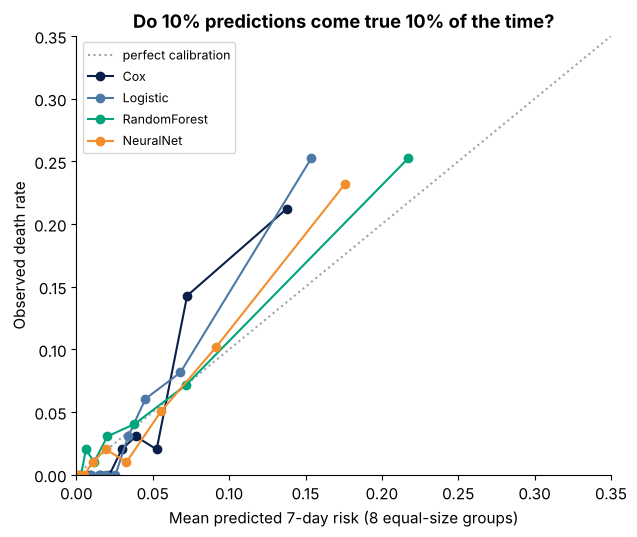

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 0.35], [0, 0.35], ":", color=GREY, label="perfect calibration")
for m in MODELS:
    fp, mp = calibration_curve(yt, P[m]["test"], n_bins=8, strategy="quantile")
    ax.plot(mp, fp, "o-", color=COLORS[m], label=m)
ax.set_xlim(0, 0.35); ax.set_ylim(0, 0.35)
ax.set_xlabel("Mean predicted 7-day risk (8 equal-size groups)"); ax.set_ylabel("Observed death rate")
ax.set_title("Do 10% predictions come true 10% of the time?"); ax.legend(fontsize=9); plt.tight_layout(); plt.show()

**What this shows**
- All four models are reasonable at low risk, where most patients sit
- In the highest-risk group, Cox and logistic regression predict about 14 to 16% while about 21 to 25% of those patients died: they **underestimate** the sickest patients
- The calibrated forest and network sit closer to the diagonal there, thanks to Platt scaling on validation patients
- Each point is a group of about 99 patients, and the top groups hold only about 20 deaths, so small gaps are uncertain

# 4. The weighted-loss trap

Deaths are rare, so a common fix is to give each death more weight during training. In PyTorch this is the `pos_weight` setting of `BCEWithLogitsLoss`: here each death counts as many times as needed to balance the survivors

What does that do to the network?

,ordinary loss,weighted loss (deaths x18)
AUROC,0.852,0.860
mean predicted risk,0.047,0.365
alerts per 100 at 10% threshold,15.482,97.208
deaths flagged (of 42),27.000,42.000
observed death rate,0.053,0.053


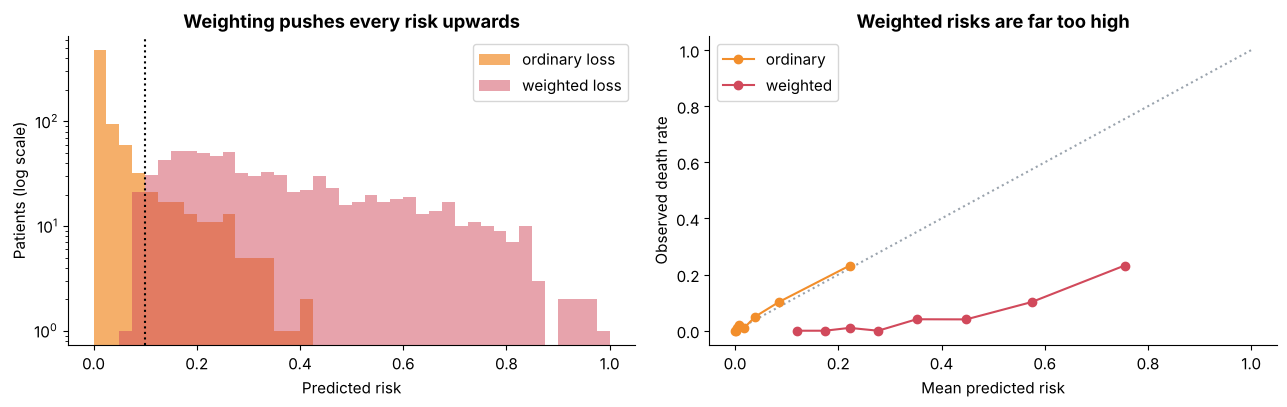

In [7]:
pw = (Y["train"] == 0).sum() / (Y["train"] == 1).sum()
nets_w = [train_net(make_mlp(XS["train"].shape[1], s), XS["train"], Y["train"], XS["val"], Y["val"], s, pos_weight=pw) for s in SEEDS]
p_w = np.mean([predict(m, XS["test"]) for m in nets_w], axis=0)
p_u = RAW["NeuralNet"]["test"]

cmp = pd.DataFrame({"ordinary loss": [roc_auc_score(yt, p_u), p_u.mean(), 100 * (p_u >= 0.10).mean(), ((p_u >= 0.10) & (yt == 1)).sum()],
                    f"weighted loss (deaths x{pw:.0f})": [roc_auc_score(yt, p_w), p_w.mean(), 100 * (p_w >= 0.10).mean(), ((p_w >= 0.10) & (yt == 1)).sum()]},
                   index=["AUROC", "mean predicted risk", "alerts per 100 at 10% threshold", f"deaths flagged (of {yt.sum()})"])
cmp.loc["observed death rate"] = [yt.mean(), yt.mean()]
display(cmp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(0, 1, 41)
axes[0].hist(p_u, bins=bins, color=ORANGE, alpha=0.7, label="ordinary loss")
axes[0].hist(p_w, bins=bins, color=RED, alpha=0.5, label="weighted loss")
axes[0].axvline(0.1, color="black", ls=":"); axes[0].set_yscale("log")
axes[0].set_xlabel("Predicted risk"); axes[0].set_ylabel("Patients (log scale)"); axes[0].legend()
axes[0].set_title("Weighting pushes every risk upwards")
axes[1].plot([0, 1], [0, 1], ":", color=GREY)
for p, c, lab in [(p_u, ORANGE, "ordinary"), (p_w, RED, "weighted")]:
    fp, mp = calibration_curve(yt, p, n_bins=8, strategy="quantile"); axes[1].plot(mp, fp, "o-", color=c, label=lab)
axes[1].set_xlabel("Mean predicted risk"); axes[1].set_ylabel("Observed death rate"); axes[1].legend()
axes[1].set_title("Weighted risks are far too high"); plt.tight_layout(); plt.show()

**What this shows** (numbers from the table above)
- Ranking barely moves: AUROC 0.852 with ordinary loss, 0.860 with weighted loss
- The risk numbers explode: the average predicted risk jumps from 4.7% to 36.5%, while the real death rate is 5.3%
- At a 10% threshold the weighted network alerts on **97 of every 100 patients**. It "catches" all 42 deaths only because it flags almost everyone

> **Pitfall:** weighting rare cases is a training choice, not a free improvement. It distorts the probabilities. If you weight, recalibrate on validation patients before anyone reads the output as a risk

# 5. From scores to decisions: two ways to compare

A ranking score does not tell a clinical team what happens on the ward. We compare the models under two operating conditions that answer **different questions**

| Condition | Question it answers |
|---|---|
| **Same risk threshold (10%)** | If the team acts on anyone above 10% risk, how many alerts and caught deaths does each model give? |
| **Same review capacity (top 10%)** | If the team can review only 79 of 788 patients, which model puts the most deaths on that list? |

**Net benefit** at a 10% threshold counts caught deaths minus false alarms, where each false alarm costs 10/90 of a caught death, per patient (notebook 03, section 9)

,alerts_per_100 @10%,deaths_caught @10%,net_benefit @10%,deaths_in_top_79
model,,,,
Cox,9.3909,18,0.0149,18
Logistic,8.5025,20,0.0188,21
RandomForest,11.6751,25,0.0223,23
NeuralNet,16.3706,27,0.0199,17


,net benefit gap vs Cox,ci_low,ci_high
Logistic,0.0038,-0.0044,0.0125
RandomForest,0.0073,-0.0031,0.0180
NeuralNet,0.0049,-0.0038,0.0147


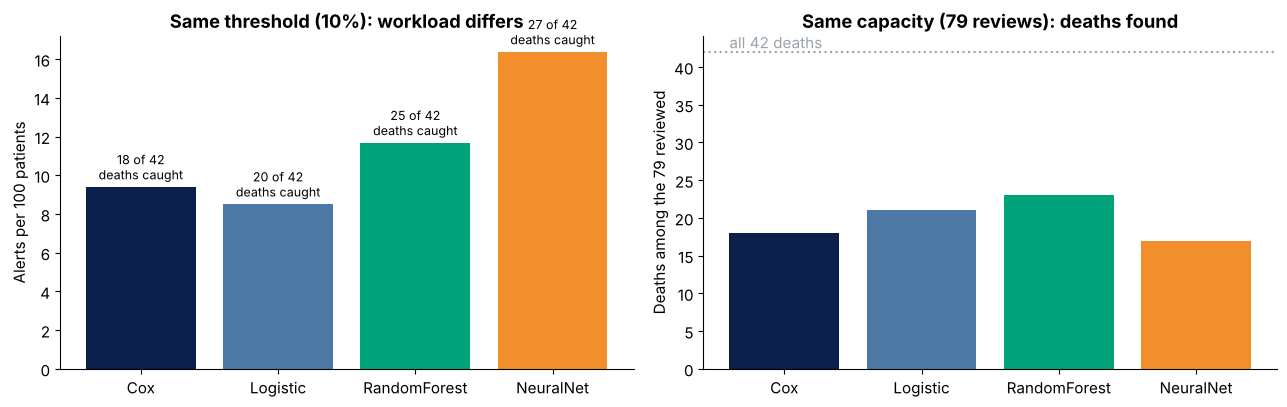

In [8]:
T = 0.10
CAP = int(round(0.10 * len(yt)))
def net_benefit(y_, p_, t):
    f = p_ >= t; return (f & (y_ == 1)).sum() / len(y_) - (f & (y_ == 0)).sum() / len(y_) * t / (1 - t)

rows = []
for m in MODELS:
    p = P[m]["test"]; f = p >= T
    top = np.argsort(-p)[:CAP]
    rows.append({"model": m, "alerts_per_100 @10%": 100 * f.mean(), "deaths_caught @10%": int((f & (yt == 1)).sum()),
                 "net_benefit @10%": net_benefit(yt, p, T), f"deaths_in_top_{CAP}": int(yt[top].sum())})
ops = pd.DataFrame(rows).set_index("model")
display(ops.round(4))

nb_ci = {}
for m in MODELS[1:]:
    g = np.array([net_benefit(yt[b], P[m]["test"][b], T) - net_benefit(yt[b], P["Cox"]["test"][b], T) for b in B])
    nb_ci[m] = (net_benefit(yt, P[m]["test"], T) - net_benefit(yt, P["Cox"]["test"], T), np.percentile(g, 2.5), np.percentile(g, 97.5))
display(pd.DataFrame(nb_ci, index=["net benefit gap vs Cox", "ci_low", "ci_high"]).T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(MODELS))
axes[0].bar(x, ops["alerts_per_100 @10%"], color=[COLORS[m] for m in MODELS])
for k, m in enumerate(MODELS):
    axes[0].text(k, ops.loc[m, "alerts_per_100 @10%"] + 0.4, f"{ops.loc[m, 'deaths_caught @10%']} of {yt.sum()}\ndeaths caught", ha="center", fontsize=9)
axes[0].set_xticks(x); axes[0].set_xticklabels(MODELS); axes[0].set_ylabel("Alerts per 100 patients")
axes[0].set_title("Same threshold (10%): workload differs")
axes[1].bar(x, ops[f"deaths_in_top_{CAP}"], color=[COLORS[m] for m in MODELS])
axes[1].axhline(yt.sum(), color=GREY, ls=":"); axes[1].text(-0.4, yt.sum() + 0.5, f"all {yt.sum()} deaths", color=GREY)
axes[1].set_xticks(x); axes[1].set_xticklabels(MODELS); axes[1].set_ylabel(f"Deaths among the {CAP} reviewed")
axes[1].set_title(f"Same capacity ({CAP} reviews): deaths found"); plt.tight_layout(); plt.show()

**What this shows** (numbers from the tables above)
- **Same threshold:** at 10% risk the network raises 16.4 alerts per 100 patients and catches 27 of 42 deaths; Cox raises 9.4 alerts and catches 18. More deaths caught, but also almost twice the workload. The threshold alone does not make models comparable
- **Same capacity:** with 79 reviews, the forest finds 23 deaths, logistic regression 21, Cox 18 and the network 17
- **Net benefit:** every model beats Cox by a small amount at 10%, but every 95% interval includes zero

The network looked "best at catching deaths" under one condition and "worst" under the other. Same model, same patients: the conclusion depends on the question

## 5.1 Do the models flag the same patients?

Even with similar totals, two models can put **different people** on the review list. That matters for the patient, and for any audit of who benefits

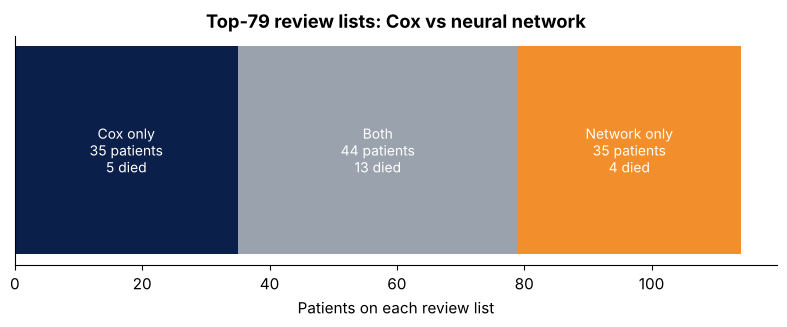

Share of patients the two lists have in common (Jaccard index, 1 = identical lists):


,Cox,Logistic,RandomForest,NeuralNet
Cox,1.00,0.39,0.32,0.39
Logistic,0.39,1.00,0.52,0.49
RandomForest,0.32,0.52,1.00,0.39
NeuralNet,0.39,0.49,0.39,1.00


In [9]:
tops = {m: set(np.argsort(-P[m]["test"])[:CAP]) for m in MODELS}
deaths = set(np.where(yt == 1)[0])
both = tops["Cox"] & tops["NeuralNet"]
only_cox, only_nn = tops["Cox"] - tops["NeuralNet"], tops["NeuralNet"] - tops["Cox"]
fig, ax = plt.subplots(figsize=(8, 3.4))
parts = [("Cox only", len(only_cox), len(only_cox & deaths), NAVY), ("Both", len(both), len(both & deaths), GREY),
         ("Network only", len(only_nn), len(only_nn & deaths), ORANGE)]
left = 0
for name, n_, d_, c in parts:
    ax.barh(0, n_, left=left, color=c); ax.text(left + n_ / 2, 0, f"{name}\n{n_} patients\n{d_} died", ha="center", va="center", color="white", fontsize=10)
    left += n_
ax.set_yticks([]); ax.set_xlabel("Patients on each review list"); ax.set_title(f"Top-{CAP} review lists: Cox vs neural network")
plt.tight_layout(); plt.show()
jac = pd.DataFrame({a: {b: len(tops[a] & tops[b]) / len(tops[a] | tops[b]) for b in MODELS} for a in MODELS})
print("Share of patients the two lists have in common (Jaccard index, 1 = identical lists):"); display(jac.round(2))

**What this shows**
- Cox and the network each put 79 patients on the list, but only 44 appear on both. 35 patients are flagged by Cox alone and 35 by the network alone
- Among those 70 "one model only" patients, 9 died: 5 found only by Cox and 4 only by the network
- The Jaccard table shows the same for every pair: lists share only about 30% to 50% of patients

> **Implication:** switching model changes **which** patients get attention, even when totals look similar. Any change of model is a clinical change and needs the same scrutiny

# 6. What 48-hour summaries hide

Every model above sees **summaries**: first, last, lowest, highest and median values. Two patients can have identical summaries and very different stories. The example below is **synthetic**, built only to make the point

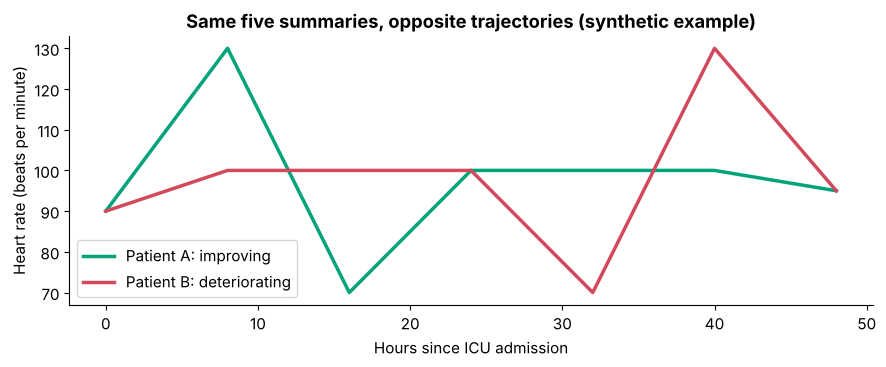

,first,last,lowest,highest,median
Patient A,90.0,95.0,70.0,130.0,100.0
Patient B,90.0,95.0,70.0,130.0,100.0


In [10]:
# Synthetic illustration (not patient data): two heart-rate series with the same first, last, lowest, highest and median values
t = np.arange(0, 49, 1.0)
a = np.interp(t, [0, 8, 16, 24, 40, 48], [90, 130, 70, 100, 100, 95])     # unstable early, then steady
b = np.interp(t, [0, 8, 24, 32, 40, 48], [90, 100, 100, 70, 130, 95])     # steady early, unstable late
def summ(s): return {"first": s[0], "last": s[-1], "lowest": s.min(), "highest": s.max(), "median": np.median(s)}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(t, a, color=GREEN, lw=2.5, label="Patient A: improving"); ax.plot(t, b, color=RED, lw=2.5, label="Patient B: deteriorating")
ax.set_xlabel("Hours since ICU admission"); ax.set_ylabel("Heart rate (beats per minute)")
ax.set_title("Same five summaries, opposite trajectories (synthetic example)"); ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame({"Patient A": summ(a), "Patient B": summ(b)}).T)

**What this shows**
- Both patients get identical inputs, so every model above must give them the same risk
- Sequence models, such as recurrent networks or transformers, can read the whole series. That is one place where deep learning can add information that summaries discard
- The price: more data, more ways to fail (gaps, different sampling rates between hospitals) and even less readable reasoning

> **Implication:** before asking "which model?", ask "what information does the model actually get?"

# 6.1 Verdict: does the network earn its place?

| Criterion | Evidence from this notebook | Favours |
|---|---|---|
| Ranking (AUROC, AUPRC) | No model separated from Cox; all intervals include zero | No one |
| Risk accuracy (calibration) | Calibrated forest and network closer for the sickest group | Forest, network (after Platt scaling) |
| Decisions at equal capacity | Forest 23, logistic 21, Cox 18, network 17 deaths in 79 reviews | Forest, logistic regression |
| Stability | Network averaged over a chosen ensemble of five seeds, because single runs flag different patients (session 1) | Cox, logistic regression |
| Interpretability and inspection | Hazard ratios and weights readable; network not | Cox, logistic regression |
| Effort to monitor and audit | Network needs version control of five models and their calibration | Cox, logistic regression |

**Verdict for this data:** the neural network does **not** earn its place. It adds opacity and effort without a demonstrated gain. A readable model is the defensible choice

This is not a general rule against deep learning. On small tabular datasets built from summaries, tree models and regression are hard to beat, a pattern also reported in larger benchmark studies ([Grinsztajn et al., 2022](https://arxiv.org/abs/2207.08815)). Deep learning tends to earn its place where readable models cannot even start: images, text, signals. That is where we go next

# Takeaways

**Key insights**
- A fair comparison fixes patients, inputs and split, and reports uncertainty, not just the top score
- Weighting rare events changes the risk numbers far more than the ranking
- Same threshold and same capacity answer different questions; report both
- Similar totals can hide different patients on the list

**Common pitfalls**
- Declaring a winner from a 0.01 AUROC gap with about 40 events
- Using weighted-loss outputs as probabilities
- Choosing the threshold on test patients
- Assuming more flexible models always use more information; here every model saw the same summaries

**What this means for healthcare decision makers**
- Ask for the gap **and** its confidence interval, on the same patients
- Ask what each alert triggers and how many the team can handle
- When a readable model performs as well, the burden of proof sits with the black box

**Next session:** images, where readable models struggle and deep learning usually earns its place, and a data trap that made published results look better than they were

**Check your understanding**
1. Why is the paired bootstrap fairer than comparing two separate confidence intervals?
2. Why did weighting deaths barely change AUROC but change alerts a lot?
3. Your hospital can review 50 patients a day. Which of the two operating conditions should you use?